In [ ]:
import pandas as pd
import numpy as np
import datetime as dt

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx'
print("Downloading dataset (this might take a minute)...")
online_retail_df = pd.read_excel(url)
print("Dataset loaded successfully!")
display(online_retail_df.head())

Dataset loaded successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Process the Real Dataset to Extract RFM Features

In [ ]:
online_retail_df = online_retail_df.dropna(subset=['CustomerID'])
online_retail_df = online_retail_df[online_retail_df['Quantity'] > 0]
online_retail_df = online_retail_df[online_retail_df['UnitPrice'] > 0]

online_retail_df['TotalAmount'] = online_retail_df['Quantity'] * online_retail_df['UnitPrice']

snapshot_date = online_retail_df['InvoiceDate'].max() + dt.timedelta(days=1)

rfm_df = online_retail_df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
}).reset_index()

rfm_df.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
}, inplace=True)

rfm_df['CustomerID'] = rfm_df['CustomerID'].astype(int)

display(rfm_df.head())

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
features = ['Recency', 'Frequency', 'Monetary']
scaler = StandardScaler()
scaled_features = scaler.fit_transform(rfm_df[features])

scaled_df = pd.DataFrame(scaled_features, columns=features)
display(scaled_df.head())

,Recency,Frequency,Monetary
0,2.334574,-0.425097,8.358668
1,-0.905340,0.354417,0.250966
2,-0.175360,-0.035340,-0.028596
3,-0.735345,-0.425097,-0.033012
4,2.174578,-0.425097,-0.191347


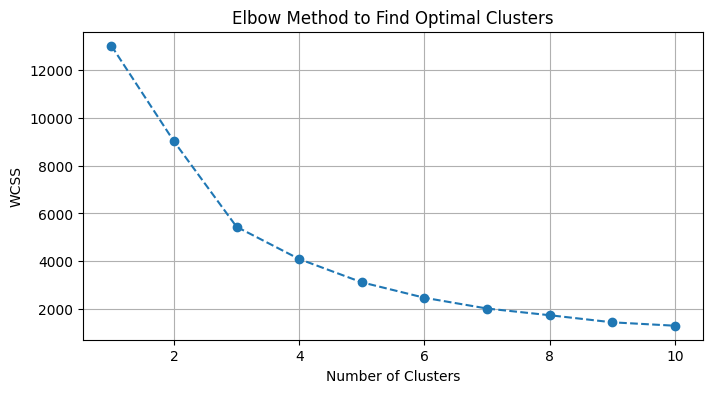

In [ ]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_df)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method to Find Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

Let's assume the optimal number of clusters is 4 and fit our K-Means model.

In [ ]:
kmeans = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
rfm_df['KMeans_Cluster'] = kmeans.fit_predict(scaled_df)
print("Cluster distribution under K-Means:")
print(rfm_df['KMeans_Cluster'].value_counts())

Cluster distribution under K-Means:
KMeans_Cluster
0    3054
1    1067
3     204
2      13
Name: count, dtype: int64


In [ ]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
rfm_df['DBSCAN_Cluster'] = dbscan.fit_predict(scaled_df)
print("Cluster distribution under DBSCAN (-1 represents noise):")
print(rfm_df['DBSCAN_Cluster'].value_counts())

Cluster distribution under DBSCAN (-1 represents noise):
DBSCAN_Cluster
 0    4284
-1      54
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


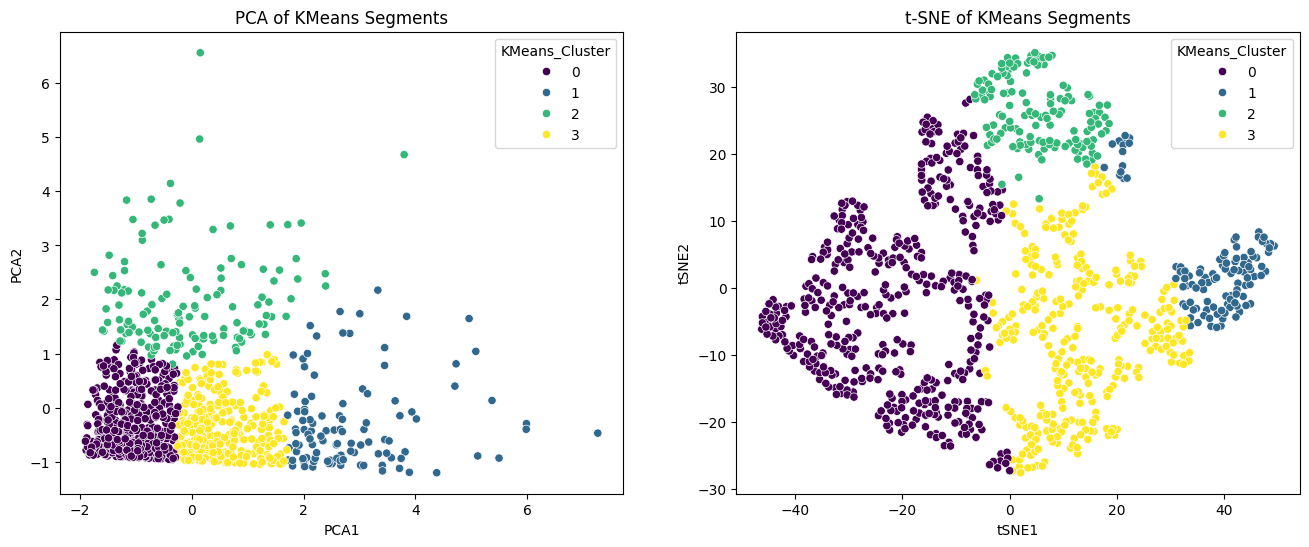

In [ ]:
pca = PCA(n_components=2, random_state=42)
pca_results = pca.fit_transform(scaled_df)
rfm_df['PCA1'] = pca_results[:, 0]
rfm_df['PCA2'] = pca_results[:, 1]

tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
tsne_results = tsne.fit_transform(scaled_df)
rfm_df['tSNE1'] = tsne_results[:, 0]
rfm_df['tSNE2'] = tsne_results[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x='PCA1', y='PCA2', hue='KMeans_Cluster', palette='viridis', data=rfm_df, ax=axes[0])
axes[0].set_title('PCA of KMeans Segments')

sns.scatterplot(x='tSNE1', y='tSNE2', hue='KMeans_Cluster', palette='viridis', data=rfm_df, ax=axes[1])
axes[1].set_title('t-SNE of KMeans Segments')

plt.show()

In [ ]:
personas = rfm_df.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean().reset_index()

def define_persona(row):
    if row['Frequency'] > 25 and row['Monetary'] > 1000:
        return "Champions (High spenders, highly active)"
    elif row['Recency'] > 150:
        return "Lost / At-Risk Customers"
    elif row['Frequency'] < 5 and row['Monetary'] < 200:
        return "Occasional Shoppers (Low value)"
    else:
        return "Loyal / Promising Customers"

personas['Persona'] = personas.apply(define_persona, axis=1)
display(personas)

,KMeans_Cluster,Recency,Frequency,Monetary,Persona
0,0,32.324444,9.491111,433.333523,Loyal / Promising Customers
1,1,41.824074,45.444444,2485.749604,"Champions (High spenders, highly active)"
2,2,143.007407,17.925926,855.969876,Loyal / Promising Customers
3,3,31.690554,24.677524,1188.820080,Loyal / Promising Customers
